# Seoul Bike Sharing Demand Prediction - Regression Track

## Capstone Project - Review 1

**Objective:** Predict the hourly count of rented bikes in Seoul based on weather, environmental, and calendar features.

**Reproducibility:** Global `random_state=42` is strictly enforced.

**Leakage Prevention:** All transformations, scalers, and encoders are strictly fitted on the training split only.

In [1]:
# Core Imports & Global Configuration
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Reproducibility seed
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

print("Regression notebook initialized. Random state set to 42.")

Regression notebook initialized. Random state set to 42.


## Phase 2: Exploratory Data Analysis (EDA)

In this phase, we perform an exhaustive audit of the Seoul Bike Sharing dataset:
1. **Data Ingestion & Integrity Audit:** Clean headers, inspect data types, detect missing values.
2. **Target Variable Analysis (`rented_bike_count`):** Distribution shape, skewness, zero-demand hours.
3. **Temporal & Seasonal Patterns:** Hourly peak commuter trends, day/night cycles, and seasonal shifts.
4. **Environmental & Weather Dynamics:** Correlation with temperature, humidity, solar radiation, and rainfall.
5. **Multicollinearity Screening:** Feature-to-feature correlation analysis.

In [2]:
# 1. Load Dataset and Standardize Column Headers
raw_bike_df = pd.read_csv('../data/SeoulBikeData.csv', encoding='unicode_escape')

# Clean column names to standard lower_snake_case without special characters
bike_df = raw_bike_df.copy()
bike_df.columns = [
    'date',
    'rented_bike_count',
    'hour',
    'temperature',
    'humidity',
    'wind_speed',
    'visibility',
    'dew_point_temperature',
    'solar_radiation',
    'rainfall',
    'snowfall',
    'seasons',
    'holiday',
    'functioning_day'
]

print(f"Dataset Shape: {bike_df.shape[0]} rows, {bike_df.shape[1]} columns")
bike_df.head()

Dataset Shape: 8760 rows, 14 columns


,date,rented_bike_count,hour,temperature,humidity,wind_speed,visibility,dew_point_temperature,solar_radiation,rainfall,snowfall,seasons,holiday,functioning_day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [3]:
# 2. Data Integrity & Completeness Audit
print("=== Column Schema & Data Types ===")
print(bike_df.info())

print("\n=== Missing Values Check ===")
missing_counts = bike_df.isnull().sum()
print(missing_counts[missing_counts > 0] if missing_counts.sum() > 0 else "No missing values found across all columns.")

print("\n=== Statistical Summary (Numerical Features) ===")
bike_df.describe().T

=== Column Schema & Data Types ===
<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   8760 non-null   str    
 1   rented_bike_count      8760 non-null   int64  
 2   hour                   8760 non-null   int64  
 3   temperature            8760 non-null   float64
 4   humidity               8760 non-null   int64  
 5   wind_speed             8760 non-null   float64
 6   visibility             8760 non-null   int64  
 7   dew_point_temperature  8760 non-null   float64
 8   solar_radiation        8760 non-null   float64
 9   rainfall               8760 non-null   float64
 10  snowfall               8760 non-null   float64
 11  seasons                8760 non-null   str    
 12  holiday                8760 non-null   str    
 13  functioning_day        8760 non-null   str    
dtypes: float64(6), int64(4), str(4)


,count,mean,std,min,25%,50%,75%,max
rented_bike_count,8760.0,704.602055,644.997468,0.0,191.00,504.50,1065.25,3556.00
hour,8760.0,11.500000,6.922582,0.0,5.75,11.50,17.25,23.00
temperature,8760.0,12.882922,11.944825,-17.8,3.50,13.70,22.50,39.40
humidity,8760.0,58.226256,20.362413,0.0,42.00,57.00,74.00,98.00
wind_speed,8760.0,1.724909,1.036300,0.0,0.90,1.50,2.30,7.40
visibility,8760.0,1436.825799,608.298712,27.0,940.00,1698.00,2000.00,2000.00
dew_point_temperature,8760.0,4.073813,13.060369,-30.6,-4.70,5.10,14.80,27.20
solar_radiation,8760.0,0.569111,0.868746,0.0,0.00,0.01,0.93,3.52
rainfall,8760.0,0.148687,1.128193,0.0,0.00,0.00,0.00,35.00
snowfall,8760.0,0.075068,0.436746,0.0,0.00,0.00,0.00,8.80


In [4]:
# 3. Categorical Variables Audit
cat_cols = ['seasons', 'holiday', 'functioning_day']
for col in cat_cols:
    print(f"--- Value Counts: {col} ---")
    print(bike_df[col].value_counts())
    print()

--- Value Counts: seasons ---
seasons
Spring    2208
Summer    2208
Autumn    2184
Winter    2160
Name: count, dtype: int64

--- Value Counts: holiday ---
holiday
No Holiday    8328
Holiday        432
Name: count, dtype: int64

--- Value Counts: functioning_day ---
functioning_day
Yes    8465
No      295
Name: count, dtype: int64



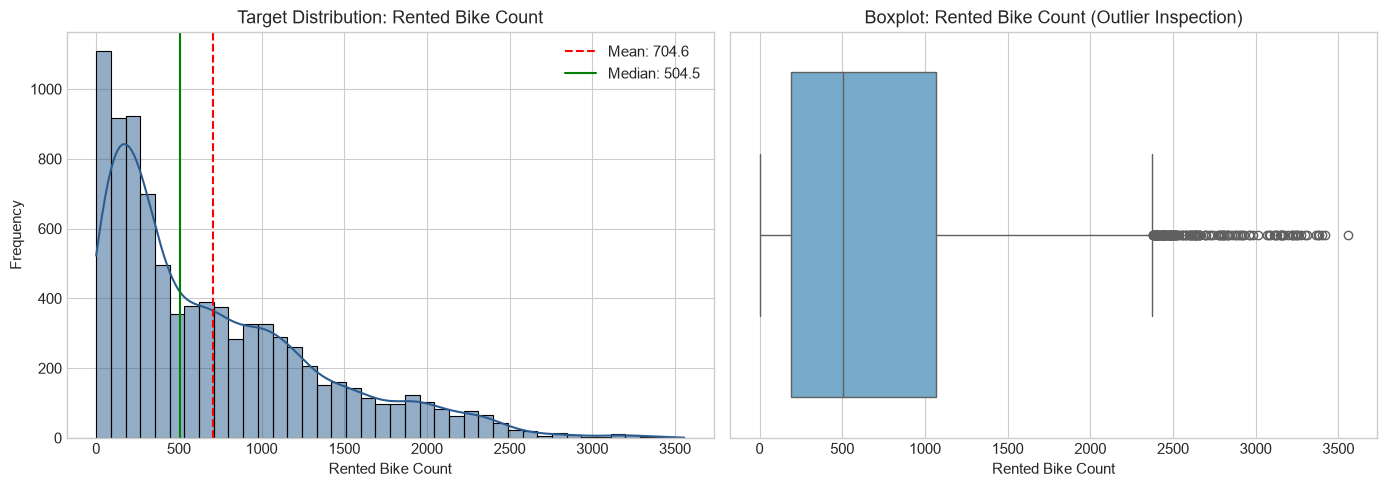

Target Skewness: 1.153 (Right-skewed, heavy right tail)


In [5]:
# 4. Target Variable Distribution (rented_bike_count)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram & KDE
sns.histplot(bike_df['rented_bike_count'], kde=True, ax=axes[0], color='#2b5c8f', bins=40)
axes[0].axvline(bike_df['rented_bike_count'].mean(), color='red', linestyle='--', label=f"Mean: {bike_df['rented_bike_count'].mean():.1f}")
axes[0].axvline(bike_df['rented_bike_count'].median(), color='green', linestyle='-', label=f"Median: {bike_df['rented_bike_count'].median():.1f}")
axes[0].set_title('Target Distribution: Rented Bike Count')
axes[0].set_xlabel('Rented Bike Count')
axes[0].set_ylabel('Frequency')
axes[0].legend()

# Boxplot to inspect extreme values
sns.boxplot(x=bike_df['rented_bike_count'], ax=axes[1], color='#6baed6')
axes[1].set_title('Boxplot: Rented Bike Count (Outlier Inspection)')
axes[1].set_xlabel('Rented Bike Count')

plt.tight_layout()
plt.show()

# Skewness calculation
target_skew = bike_df['rented_bike_count'].skew()
print(f"Target Skewness: {target_skew:.3f} (Right-skewed, heavy right tail)")

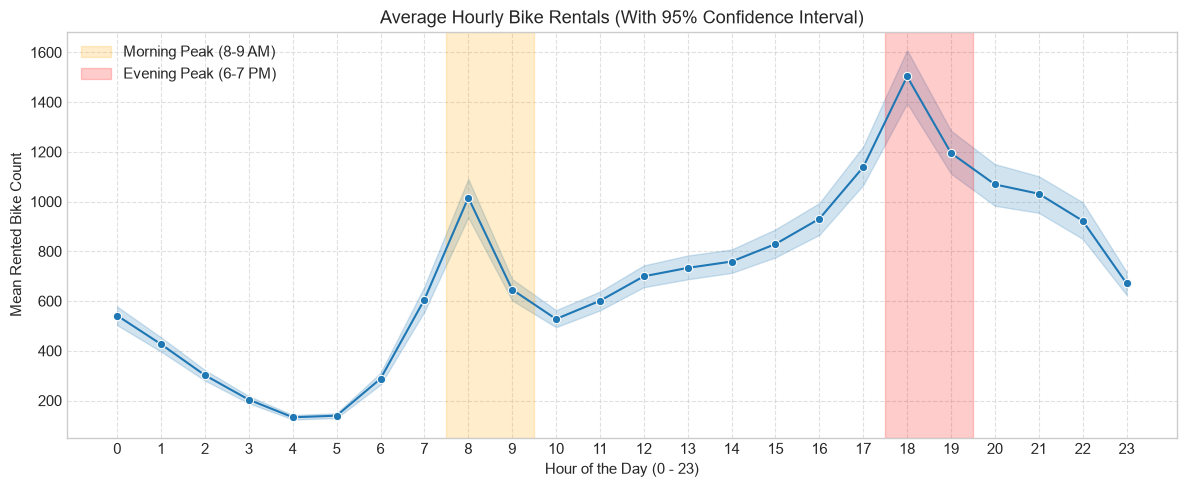

In [6]:
# 5. Temporal Dynamics: Hourly Rental Patterns
fig, ax = plt.subplots(figsize=(12, 5))
hourly_avg = bike_df.groupby('hour')['rented_bike_count'].agg(['mean', 'std']).reset_index()

sns.lineplot(data=bike_df, x='hour', y='rented_bike_count', ci=95, ax=ax, color='#1f77b4', marker='o')
ax.set_title('Average Hourly Bike Rentals (With 95% Confidence Interval)')
ax.set_xlabel('Hour of the Day (0 - 23)')
ax.set_ylabel('Mean Rented Bike Count')
ax.set_xticks(range(0, 24))
ax.grid(True, linestyle='--', alpha=0.6)

# Annotate commuter rush hours
ax.axvspan(7.5, 9.5, color='orange', alpha=0.2, label='Morning Peak (8-9 AM)')
ax.axvspan(17.5, 19.5, color='red', alpha=0.2, label='Evening Peak (6-7 PM)')
ax.legend()
plt.tight_layout()
plt.show()

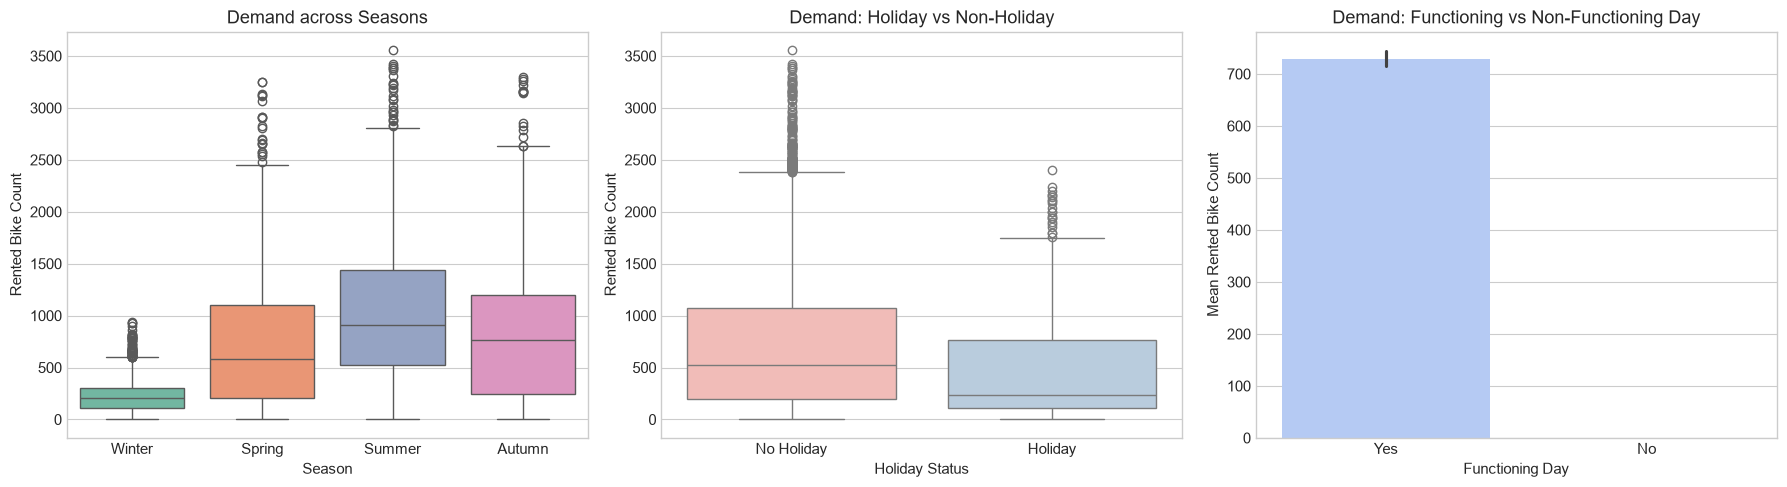

In [7]:
# 6. Seasonal & Calendar Variations
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Rentals across Seasons
sns.boxplot(data=bike_df, x='seasons', y='rented_bike_count', ax=axes[0], palette='Set2')
axes[0].set_title('Demand across Seasons')
axes[0].set_xlabel('Season')
axes[0].set_ylabel('Rented Bike Count')

# Rentals on Holidays vs Regular Days
sns.boxplot(data=bike_df, x='holiday', y='rented_bike_count', ax=axes[1], palette='Pastel1')
axes[1].set_title('Demand: Holiday vs Non-Holiday')
axes[1].set_xlabel('Holiday Status')
axes[1].set_ylabel('Rented Bike Count')

# Rentals on Functioning vs Non-Functioning Days
sns.barplot(data=bike_df, x='functioning_day', y='rented_bike_count', ax=axes[2], palette='coolwarm')
axes[2].set_title('Demand: Functioning vs Non-Functioning Day')
axes[2].set_xlabel('Functioning Day')
axes[2].set_ylabel('Mean Rented Bike Count')

plt.tight_layout()
plt.show()

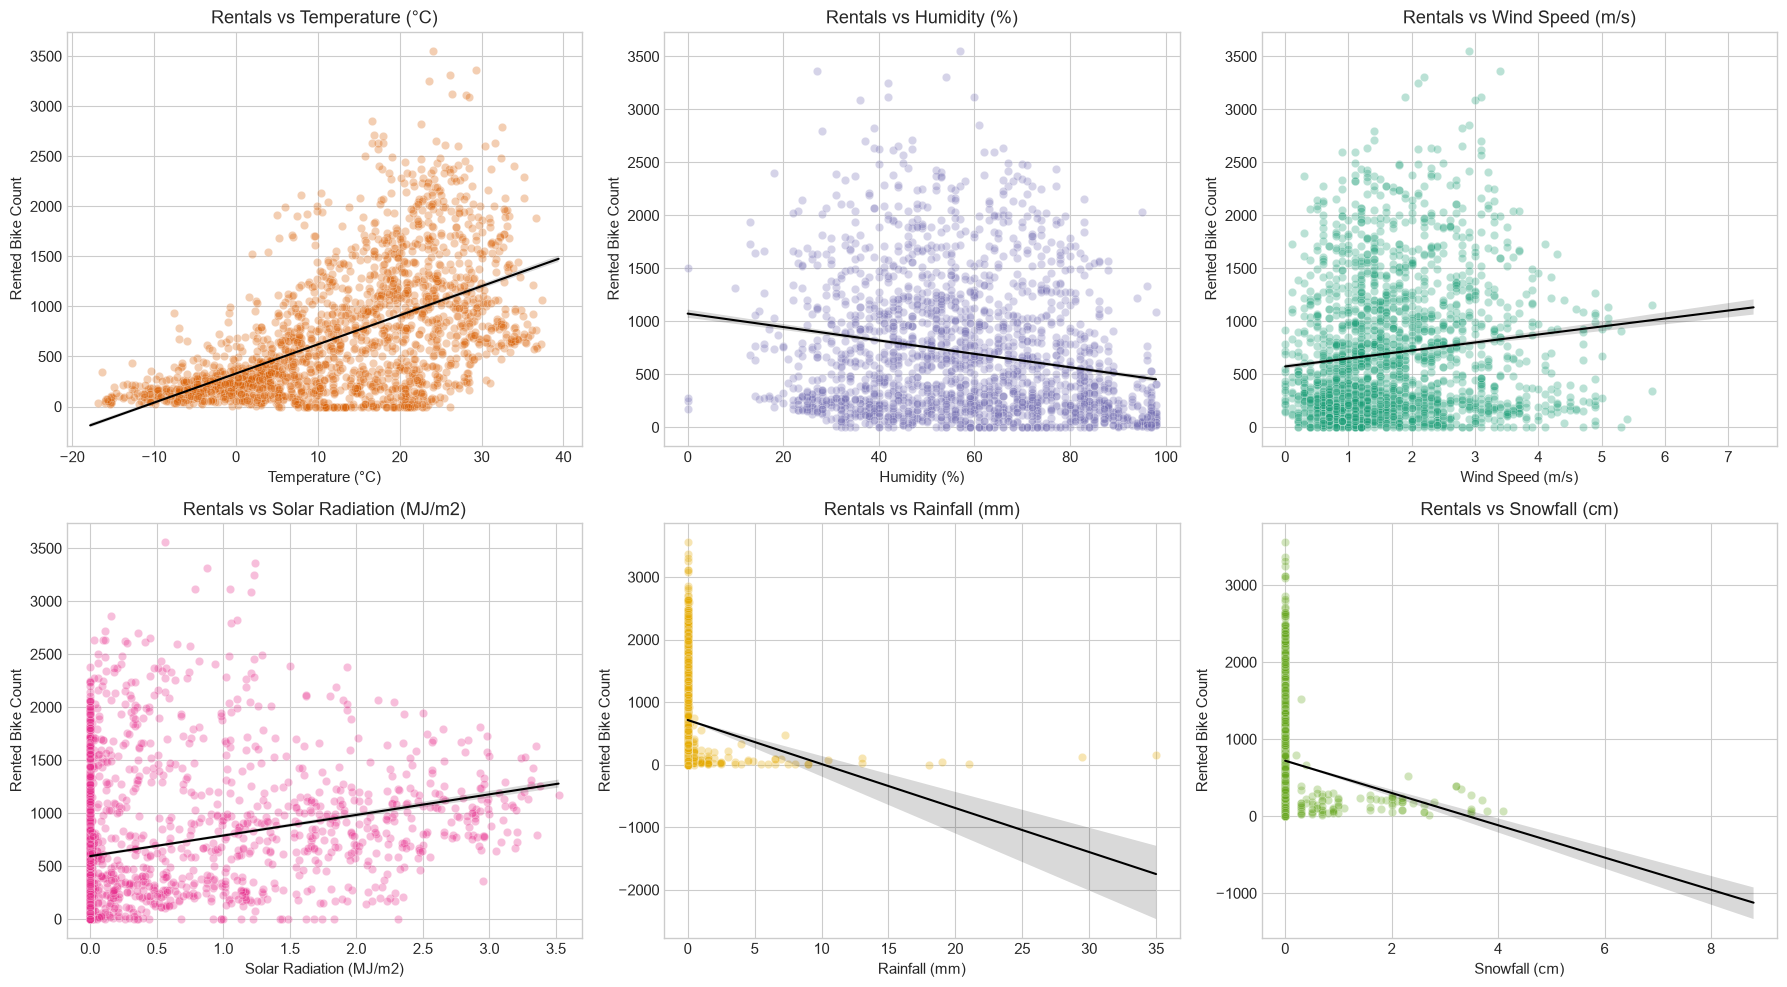

In [8]:
# 7. Weather & Environmental Relationships
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

weather_vars = [
    ('temperature', 'Temperature (°C)', '#d95f02'),
    ('humidity', 'Humidity (%)', '#7570b3'),
    ('wind_speed', 'Wind Speed (m/s)', '#1b9e77'),
    ('solar_radiation', 'Solar Radiation (MJ/m2)', '#e7298a'),
    ('rainfall', 'Rainfall (mm)', '#e6ab02'),
    ('snowfall', 'Snowfall (cm)', '#66a61e')
]

for idx, (col, label, color) in enumerate(weather_vars):
    ax = axes[idx // 3, idx % 3]
    sns.scatterplot(data=bike_df.sample(2000, random_state=RANDOM_STATE), x=col, y='rented_bike_count', alpha=0.3, ax=ax, color=color)
    sns.regplot(data=bike_df, x=col, y='rented_bike_count', scatter=False, ax=ax, color='black', line_kws={'linewidth': 1.5})
    ax.set_title(f'Rentals vs {label}')
    ax.set_xlabel(label)
    ax.set_ylabel('Rented Bike Count')

plt.tight_layout()
plt.show()

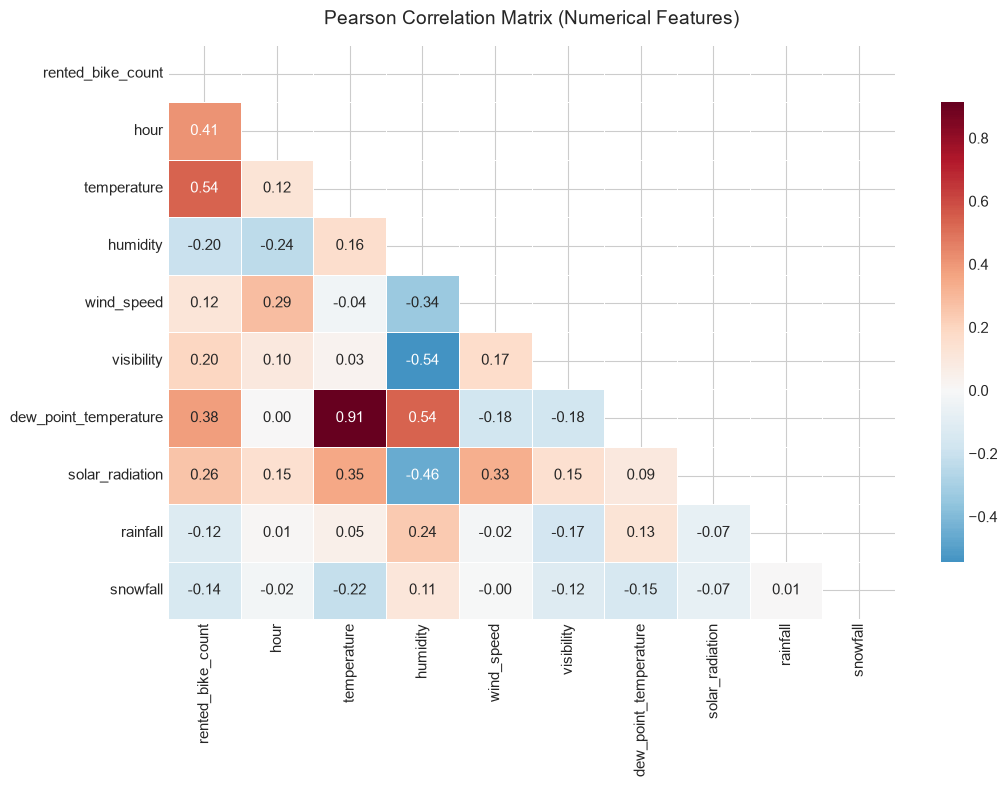

=== Correlations with Rented Bike Count ===
rented_bike_count        1.000000
temperature              0.538558
hour                     0.410257
dew_point_temperature    0.379788
solar_radiation          0.261837
visibility               0.199280
wind_speed               0.121108
rainfall                -0.123074
snowfall                -0.141804
humidity                -0.199780
Name: rented_bike_count, dtype: float64

=== High Feature-to-Feature Collinearity (|r| > 0.70) ===
Collinear Pair: temperature <--> dew_point_temperature (r = 0.913)


In [9]:
# 8. Pearson Correlation Heatmap & Multicollinearity Inspection
numeric_cols = bike_df.select_dtypes(include=[np.number]).columns
corr_matrix = bike_df[numeric_cols].corr()

plt.figure(figsize=(11, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0, mask=mask, linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Pearson Correlation Matrix (Numerical Features)', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

# Highlight highest absolute correlations with Target and between features
print("=== Correlations with Rented Bike Count ===")
print(corr_matrix['rented_bike_count'].sort_values(ascending=False))

print("\n=== High Feature-to-Feature Collinearity (|r| > 0.70) ===")
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        col1, col2 = corr_matrix.columns[i], corr_matrix.columns[j]
        if col1 != 'rented_bike_count' and col2 != 'rented_bike_count':
            r = corr_matrix.loc[col1, col2]
            if abs(r) > 0.70:
                print(f"Collinear Pair: {col1} <--> {col2} (r = {r:.3f})")

### Phase 2 Key EDA Findings & Modeling Implications

1. **Target Distribution (
ented_bike_count):**
   * Heavily right-skewed (skewness ≈ 1.15) with positive median-mean divergence (median = 504.5, mean = 704.6).
   * Non-functioning days (unctioning_day == 'No') record strictly 0 rentals across all hours. This is a deterministic structural filter that will be handled appropriately during preprocessing.
2. **Bimodal Commuter Rhythm:**
   * Demand exhibits sharp bimodal spikes aligning with workplace transit: morning rush hour at **08:00** and evening rush hour at **18:00**.
   * Low demand is observed during early morning hours (03:00 - 05:00).
3. **Seasonal & Calendar Effects:**
   * Summer and Autumn have the highest median rental counts, whereas Winter shows steep drops due to sub-zero temperatures and snow.
4. **Multicollinearity & Feature Redundancy:**
   * 	emperature and dew_point_temperature exhibit extremely high collinearity (r ≈ 0.91). Keeping both in unregularized linear models risks variance inflation, highlighting the importance of Ridge/Lasso regularization and tree-based methods in Phase 4.